# Trabajo Práctico N° 3: SVM y Random Forest

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, Federico

Recomendamos uno de 10 cultivos a partir de 16 variables de suelo y clima. Todas las particiones, validaciones cruzadas y modelos usan random_state=13.

In [1]:
# Importo las librerías y fijo la semilla
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 13  # random_state de todas las particiones, validaciones cruzadas y modelos


# Defino una función que agrega "Figura n" debajo del gráfico
def numerar(n):
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.figtext(0.5, 0.01, f"Figura {n}", ha="center", va="bottom")


## 1. Preparación de datos

El archivo crop_recommendation_geo.csv tiene 50004 filas y 17 columnas (50005 líneas con el encabezado, que son las 50005 muestras que menciona el enunciado). La variable objetivo se llama clase en el CSV y Clase en el enunciado. Usamos los nombres del CSV: el enunciado escribe temp_mim_mensual donde el archivo dice temp_min_mensual.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| N | Nitrógeno total en el suelo (0-30 cm) | Numérica continua | Predictora |
| P | Fósforo disponible para las plantas (Olsen) | Numérica continua | Predictora |
| exch_bases | Bases intercambiables totales (Ca + Mg + K + Na) de la capa superficial del suelo | Numérica continua | Predictora |
| ph | pH del suelo en agua (0-30 cm) | Numérica continua | Predictora |
| soc | Carbono orgánico del suelo (0-30 cm) | Numérica continua | Predictora |
| arcilla | Fracción arcillosa (0-30 cm) | Numérica continua | Predictora |
| arena | Fracción de arena (0-30 cm) | Numérica continua | Predictora |
| cec | Capacidad de intercambio catiónico | Numérica continua | Predictora |
| temperatura | Temperatura media anual del aire | Numérica continua | Predictora |
| temp_min_mensual | Temperatura media del mes más frío | Numérica continua | Predictora |
| temp_max_mensual | Temperatura media del mes más cálido | Numérica continua | Predictora |
| humedad | Humedad relativa media anual | Numérica continua | Predictora |
| lluvia | Precipitación anual | Numérica discreta | Predictora |
| estacionalidad_lluvias | Coeficiente de variación de la precipitación mensual (BIO15) | Numérica continua | Predictora |
| radiacion_solar | Radiación solar incidente media anual | Numérica continua | Predictora |
| elevacion | Altura sobre el nivel del mar | Numérica discreta | Predictora |
| clase | Cultivo recomendado (algodon, arroz, banana, cafe, coco, frijol, garbanzo, lenteja, maiz y manzana) | Categórica nominal | Objetivo |

Hipótesis: las tres variables de temperatura están muy correlacionadas entre sí, P, soc, lluvia y elevacion tienen una cola larga a la derecha, y como el conjunto se modificó a propósito esperamos nulos, duplicados y valores fuera de rango.

In [2]:
# REVISAR: no está en los apuntes. decimal="," lee los decimales con coma, porque el CSV usa ";" como separador y "," como decimal
df = pd.read_csv("crop_recommendation_geo.csv", sep=";", decimal=",")
display(df.head())
df.info()


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,1.353,6.689,13.5,7.233,11.167,24.867,31.017,16.867,24.868,15.185,31.804,65.161,1148,126.689,19.228,96,arroz
1,1.855,11.072,16.9,6.083,15.583,37.217,25.750,15.933,23.829,16.888,29.372,83.058,1740,81.048,15.206,3,arroz
2,1.727,14.273,29.0,6.400,15.717,26.667,35.000,23.683,18.029,7.566,27.969,77.170,1108,65.502,11.994,316,arroz
3,1.442,7.527,3.0,6.283,18.067,36.700,27.300,19.083,18.042,6.620,28.075,78.908,1483,51.357,13.621,343,arroz
4,1.920,12.067,15.8,6.983,16.600,28.733,29.450,18.533,16.284,7.726,24.241,59.990,471,83.554,16.836,6,arroz


<class 'pandas.DataFrame'>
RangeIndex: 50004 entries, 0 to 50003
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       50004 non-null  float64
 1   P                       50004 non-null  float64
 2   exch_bases              50004 non-null  float64
 3   ph                      50003 non-null  float64
 4   soc                     50004 non-null  float64
 5   arcilla                 50004 non-null  float64
 6   arena                   50004 non-null  float64
 7   cec                     50003 non-null  float64
 8   temperatura             50004 non-null  float64
 9   temp_min_mensual        50004 non-null  float64
 10  temp_max_mensual        50004 non-null  float64
 11  humedad                 50003 non-null  float64
 12  lluvia                  50004 non-null  int64  
 13  estacionalidad_lluvias  50004 non-null  float64
 14  radiacion_solar         50004 non-null  float64
 

El CSV separa las columnas con punto y coma y escribe los decimales con coma. Sin decimal="," pandas lee como texto las 14 columnas con decimales y también clase. El parámetro no aparece en los apuntes y lo agregamos para que esas columnas se lean como números.

Con la lectura correcta, df tiene 16 predictoras numéricas (14 float y 2 enteras: lluvia y elevacion) y clase como texto. ph, cec y humedad tienen un nulo cada una.

In [3]:
# Reviso nulos, duplicados, descriptivas y asimetría de las variables predictoras
num_cols = df.columns.drop("clase")
print("Columnas con nulos:", df.isna().any().sum())
print("Valores nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("Filas duplicadas:", df.duplicated().sum())
print("\nAsimetría de cada variable:")
print(df[num_cols].skew().round(2).to_string())
df.describe().T.round(2)


Columnas con nulos: 3
Valores nulos por columna:
ph         1
cec        1
humedad    1
Filas duplicadas: 198

Asimetría de cada variable:
N                         1.78
P                         3.90
exch_bases                0.84
ph                        0.13
soc                       4.74
arcilla                   0.16
arena                     0.54
cec                       0.95
temperatura              -0.79
temp_min_mensual         -0.85
temp_max_mensual         -0.29
humedad                  -0.32
lluvia                    1.25
estacionalidad_lluvias    0.43
radiacion_solar          -0.22
elevacion                 2.41


,count,mean,std,min,25%,50%,75%,max
N,50004.0,1.81,0.96,0.26,1.10,1.63,2.27,15.10
P,50004.0,10.31,11.11,0.00,3.68,6.67,12.89,180.00
exch_bases,50004.0,17.86,11.98,0.10,7.00,16.00,26.50,143.00
ph,50003.0,6.48,1.02,4.05,5.55,6.50,7.35,25.32
soc,50004.0,24.34,26.46,1.02,11.02,18.12,27.18,322.82
arcilla,50004.0,31.24,8.05,2.40,25.63,31.03,36.77,142.38
arena,50004.0,36.90,13.56,0.88,28.02,34.68,45.03,94.50
cec,50003.0,20.46,7.74,3.72,15.55,19.55,24.23,70.82
temperatura,50004.0,19.24,7.72,-7.38,14.22,21.96,25.79,44.63
temp_min_mensual,50004.0,11.91,12.63,-27.87,3.10,16.44,22.10,27.92


Inspección: hay 3 valores nulos (uno en ph, uno en cec y uno en humedad) y 198 filas duplicadas. Los máximos de tres variables salen del rango físico: ph llega a 25.32, humedad a 148.14 y arcilla a 142.38, y el pH no pasa de 14 y los porcentajes no pasan de 100.

La asimetría confirma la primera parte de la hipótesis: soc (4.74), P (3.90), elevacion (2.41), N (1.78) y lluvia (1.25) tienen cola derecha. ph (0.13) y arcilla (0.16) son casi simétricas.

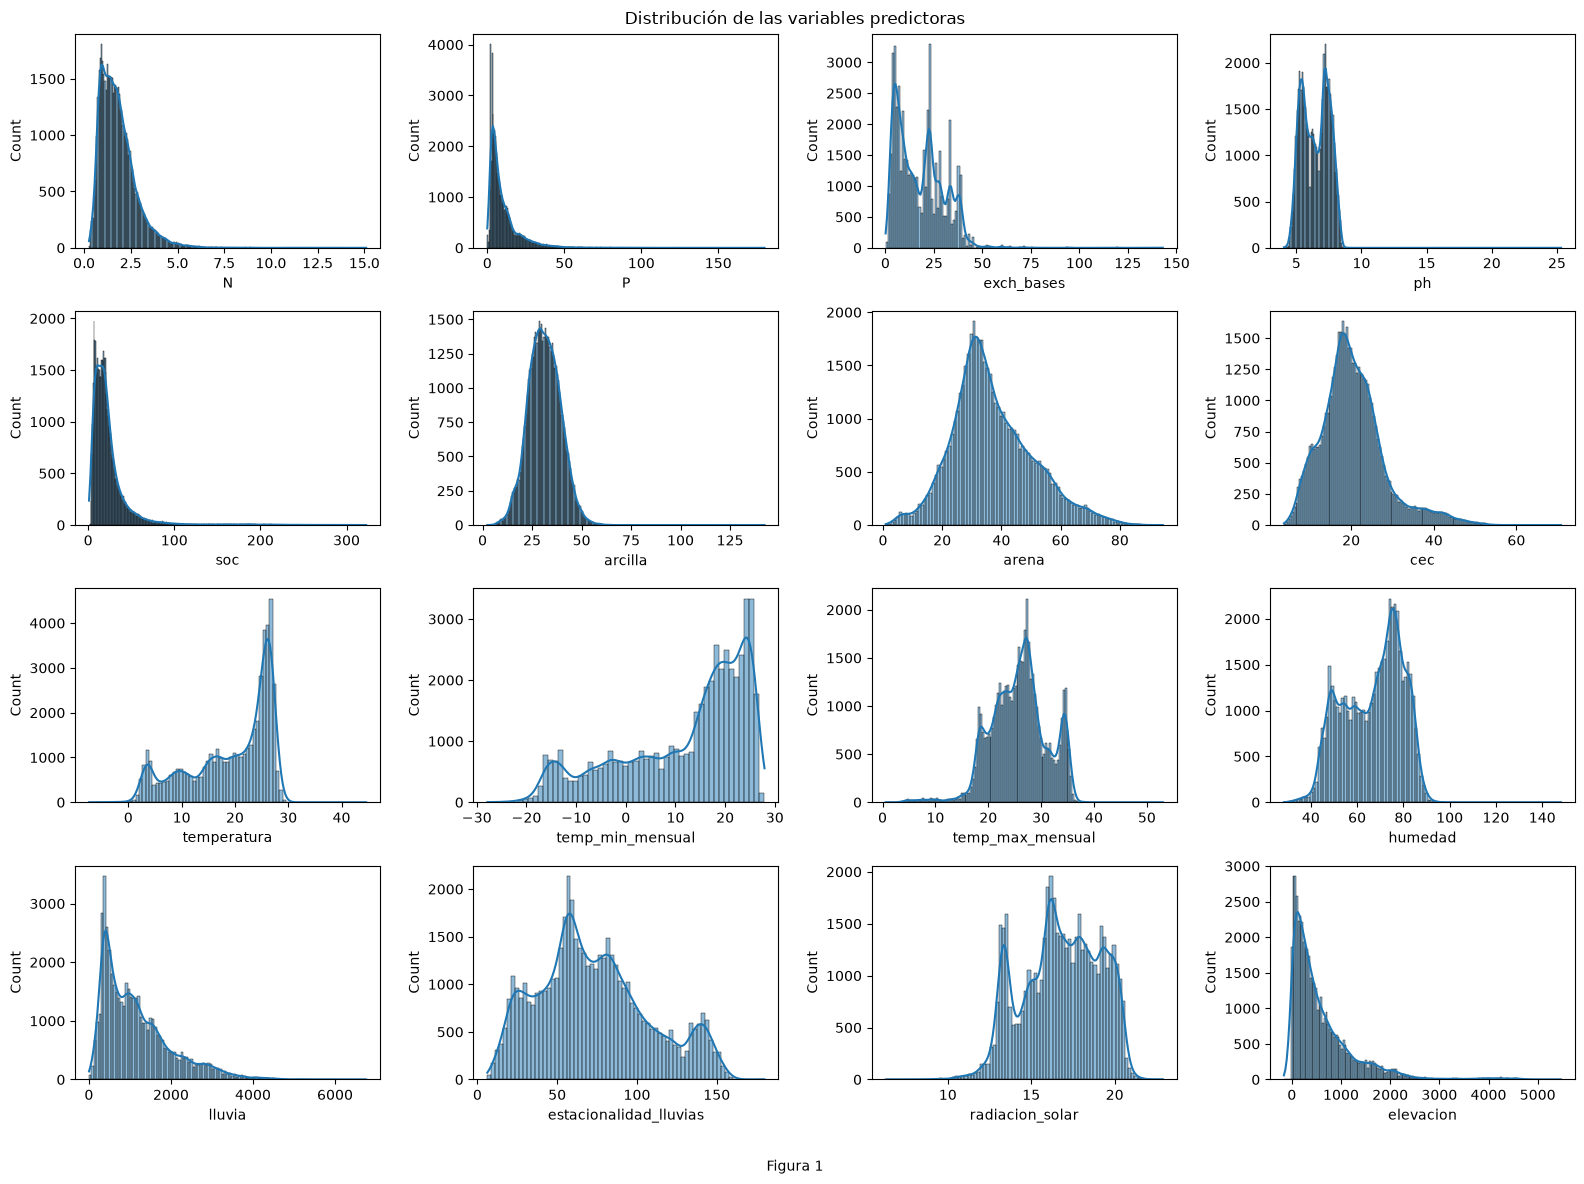

In [4]:
# Grafico la distribución de cada variable predictora
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, edgecolor="black", linewidth=0.3, ax=ax)
plt.suptitle("Distribución de las variables predictoras")
numerar(1)
plt.show()


Figura 1. N, P, soc, lluvia y elevacion se concentran cerca de cero con una cola larga hacia la derecha: P tiene mediana 6.67 y máximo 180, y soc tiene mediana 18.12 y máximo 322.82. temperatura y temp_min_mensual acumulan la mayor parte de los datos en valores altos, con picos cerca de 26 °C y de 25 °C, y una cola hacia valores bajos. ph tiene dos picos, cerca de 5.4 y 7.5, y su eje se estira hasta 25 por dos valores aislados. exch_bases y radiacion_solar también tienen varios picos. Los picos múltiples sugieren que los cultivos ocupan rangos distintos de cada variable, aunque la figura no separa por clase y no lo comprueba.

,Cantidad,Porcentaje
clase,,
cafe,5002,10.0
arroz,5001,10.0
manzana,5001,10.0
maiz,5000,10.0
garbanzo,5000,10.0
algodon,5000,10.0
banana,5000,10.0
frijol,5000,10.0
coco,5000,10.0


Razón clase mayoritaria / minoritaria: 1.0


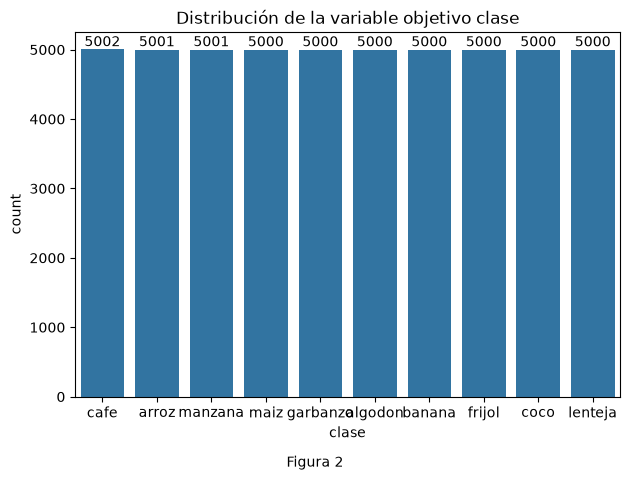

In [5]:
# Miro el balance de la variable objetivo clase
cantidad = df["clase"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df) * 100).round(2)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))

ax = sns.countplot(data=df, x="clase", order=cantidad.index)
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo clase")
numerar(2)
plt.show()


Figura 2. Las 10 clases tienen 5000 filas cada una, salvo cafe (5002), arroz (5001) y manzana (5001). La razón entre la clase mayoritaria y la minoritaria es 1.0. El enunciado menciona un leve desbalance que el archivo original no tiene: aparece recién al eliminar los duplicados.

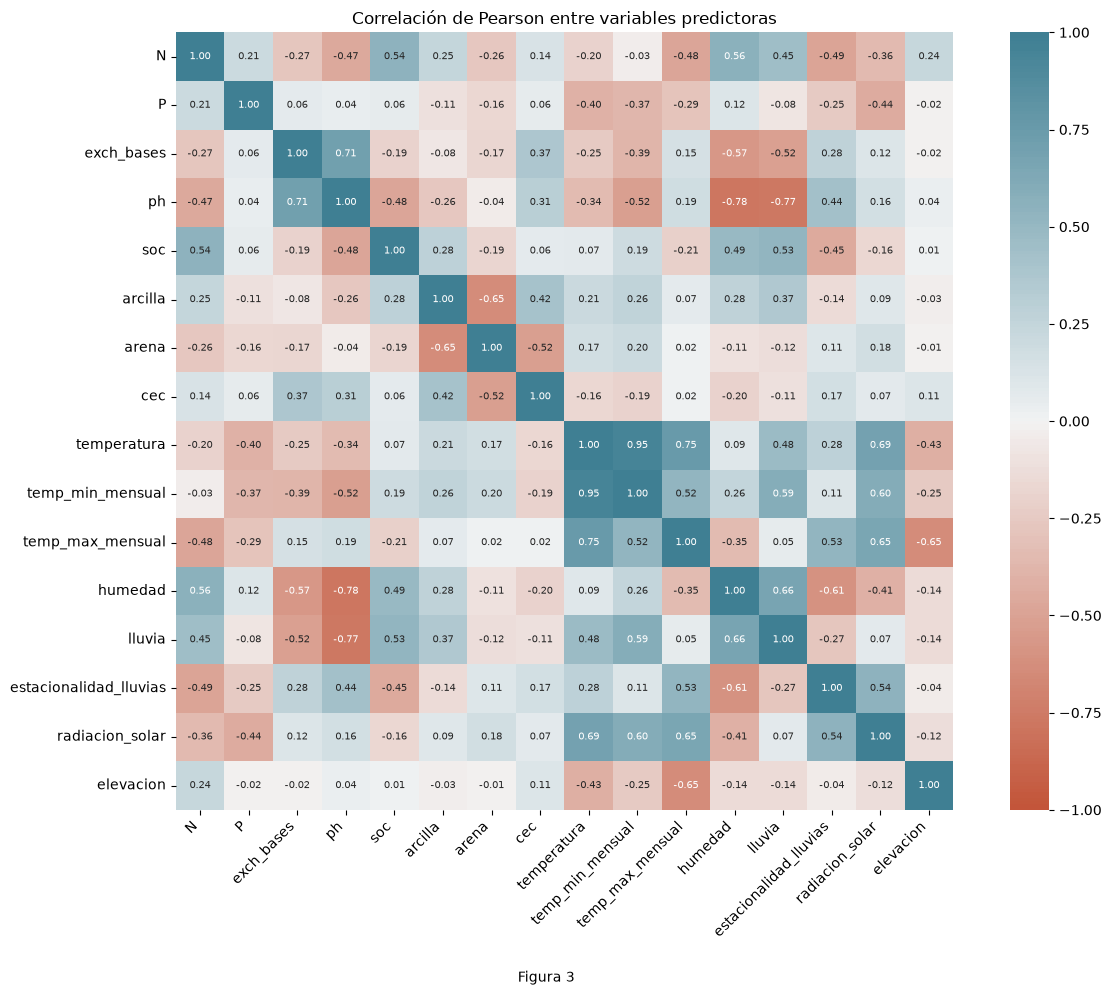

In [6]:
# Grafico la matriz de correlación de Pearson entre las variables predictoras
corr = df[num_cols].corr(method="pearson")
plt.figure(figsize=(13, 10))
ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                 cmap=sns.diverging_palette(20, 220, n=200),
                 square=True, annot=True, fmt=".2f", annot_kws={"size": 7})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right")
plt.title("Correlación de Pearson entre variables predictoras")
numerar(3)
plt.show()


Figura 3. temperatura se relaciona con temp_min_mensual (0.95) y con temp_max_mensual (0.75), pero temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí. La hipótesis sobre las temperaturas se cumple en parte. ph tiene correlación negativa alta con humedad (-0.78) y con lluvia (-0.77), y positiva con exch_bases (0.71). arcilla y arena están en oposición (-0.65), y temp_max_mensual con elevacion también (-0.65).

Hay varias variables redundantes. No eliminamos ninguna, porque la consigna no pide selección de variables y el SVM y el Random Forest toleran predictoras correlacionadas. En el Random Forest la importancia se reparte entre las variables correlacionadas, así que hay que leerla con cuidado.

### (a) Valores faltantes

In [7]:
# (a) Valores faltantes: muestro la fila que los contiene
display(df[df.isna().any(axis=1)])


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25085,2.773,3.891,3.8,NaN,33.017,31.333,48.217,NaN,19.355,15.852,22.09,NaN,1294,63.371,14.632,769,cafe


Los 3 nulos están en una sola fila (índice 25085, clase cafe): le faltan ph, cec y humedad. Eliminamos la fila. Es 1 de 50004 filas (0.002%) y cafe tiene 5002. Imputar con la media o la mediana reemplazaría 3 de sus 16 valores por constantes que no vienen de ninguna medición.

### (b) Registros duplicados

In [8]:
# (b) Registros duplicados: cuento cuántos hay por clase
print("Filas duplicadas:", df.duplicated().sum())
print(df[df.duplicated()]["clase"].value_counts().to_string())


Filas duplicadas: 198
clase
lenteja     109
manzana      55
algodon      14
garbanzo     12
maiz          3
frijol        3
arroz         2


Hay 198 filas duplicadas: 109 de lenteja, 55 de manzana, 14 de algodon, 12 de garbanzo, 3 de maiz, 3 de frijol y 2 de arroz. Eliminamos las copias y dejamos la primera aparición. En validación cruzada una copia en train y otra en test deja un ejemplo ya visto en el test, y las métricas salen infladas.

### (c) Posibles outliers

In [9]:
# (c) Atípicos: cuento los valores fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR] en cada variable
filas = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    filas.append({"Variable": col, "Atípicos": n, "Porcentaje": round(n / len(df) * 100, 1),
                  "Mínimo": df[col].min(), "Máximo": df[col].max()})
display(pd.DataFrame(filas).set_index("Variable"))

# Busco los valores imposibles: pH mayor que 14, humedad relativa mayor que 100 % y arcilla mayor que 100 %
imposibles = (df["ph"] > 14) | (df["humedad"] > 100) | (df["arcilla"] > 100)
display(df[imposibles])


,Atípicos,Porcentaje,Mínimo,Máximo
Variable,,,,
N,1483,3.0,0.265,15.098
P,3453,6.9,0.000,180.000
exch_bases,181,0.4,0.100,143.000
ph,2,0.0,4.050,25.317
soc,3665,7.3,1.017,322.817
arcilla,292,0.6,2.400,142.383
arena,849,1.7,0.883,94.500
cec,2162,4.3,3.717,70.817
temperatura,14,0.0,-7.377,44.626


,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
25111,10.970,3.000,0.1,25.317,16.633,33.850,53.317,13.133,23.500,21.909,24.918,82.018,17,61.612,13.901,679,cafe
30012,0.648,6.599,26.6,18.017,4.967,142.383,68.633,17.683,44.626,6.145,53.006,148.141,265,28.815,6.274,322,manzana


Por el criterio del IQR, las variables con más atípicos son soc (3665, 7.3%), P (3453, 6.9%), elevacion (2825, 5.6%), cec (2162, 4.3%), N (1483, 3.0%) y lluvia (1360, 2.7%). Todas tienen cola derecha en la Figura 1. Una precipitación, una altura o un contenido de carbono grandes son valores posibles, así que los conservamos.

Distinto es el caso de dos filas con valores imposibles. La fila 25111 (cafe) tiene ph de 25.317. La fila 30012 (manzana) tiene ph de 18.017, arcilla de 142.383 y humedad de 148.141, y además temperatura de 44.626 y temp_max_mensual de 53.006, los máximos de esas dos columnas. Las eliminamos.

In [10]:
# REVISAR: no está en los apuntes. drop_duplicates elimina las filas repetidas (deja la primera) y dropna las filas con nulos
df_clean = df[~imposibles].drop_duplicates().dropna()
print("Filas:", len(df), "->", len(df_clean), "| eliminadas:", len(df) - len(df_clean))

cantidad = df_clean["clase"].value_counts()
display(pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(df_clean) * 100).round(2)}))
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 3))


Filas: 50004 -> 49803 | eliminadas: 201


,Cantidad,Porcentaje
clase,,
banana,5000,10.04
cafe,5000,10.04
coco,5000,10.04
arroz,4999,10.04
maiz,4997,10.03
frijol,4997,10.03
garbanzo,4988,10.02
algodon,4986,10.01
manzana,4945,9.93


Razón clase mayoritaria / minoritaria: 1.022


drop_duplicates y dropna no figuran en los apuntes: el primero elimina las filas repetidas y deja la primera, y el segundo elimina las filas con algún nulo. Filtramos antes las 2 filas con valores imposibles.

El conjunto pasa de 50004 a 49803 filas. Las 201 filas eliminadas son las 198 duplicadas, la fila con nulos y las 2 con valores imposibles.

Después de limpiar, las clases quedan entre 4891 (lenteja) y 5000 (banana, cafe y coco), con razón de 1.022. Lenteja y manzana (4945) perdieron filas por los duplicados. Es un desbalance leve, y por eso usamos Precision y Recall con promedio weighted, como pide la consigna.

In [11]:
# REVISAR: no está en los apuntes. LabelEncoder se importa en U5_SVMClassifier_wine pero no se usa; acá codifica clase como enteros de 0 a 9 (orden alfabético)
le = LabelEncoder()
y = le.fit_transform(df_clean["clase"])
X = df_clean.drop(columns="clase")
print(dict(enumerate(le.classes_)))

# Estandarizo las predictoras con StandardScaler y verifico media 0 y desvío 1
X_std = StandardScaler().set_output(transform="pandas").fit_transform(X)
display(X_std.describe().loc[["mean", "std"]].round(3))


{0: 'algodon', 1: 'arroz', 2: 'banana', 3: 'cafe', 4: 'coco', 5: 'frijol', 6: 'garbanzo', 7: 'lenteja', 8: 'maiz', 9: 'manzana'}

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion
mean,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Codificación de la variable objetivo: LabelEncoder asigna 0 a algodon hasta 9 a manzana, en orden alfabético. SVC y RandomForestClassifier aceptan etiquetas de texto, pero la consigna pide codificar. LabelEncoder aparece importado en U5_SVMClassifier_wine y no se usa, por eso el comentario REVISAR. Las matrices de confusión de la Actividad 5 recuperan los nombres con le.classes_.

Estandarización: la tabla muestra media 0 y desvío 1 en las 16 variables. X_std sirve solo para esta verificación y para la Figura 4. En las Actividades 2 y 3 el StandardScaler va dentro de un make_pipeline, que lo ajusta solo con los 4 folds de entrenamiento de cada partición. Así el fold de test no influye en la media ni en el desvío. El Random Forest usa X sin estandarizar, porque no depende de la escala.

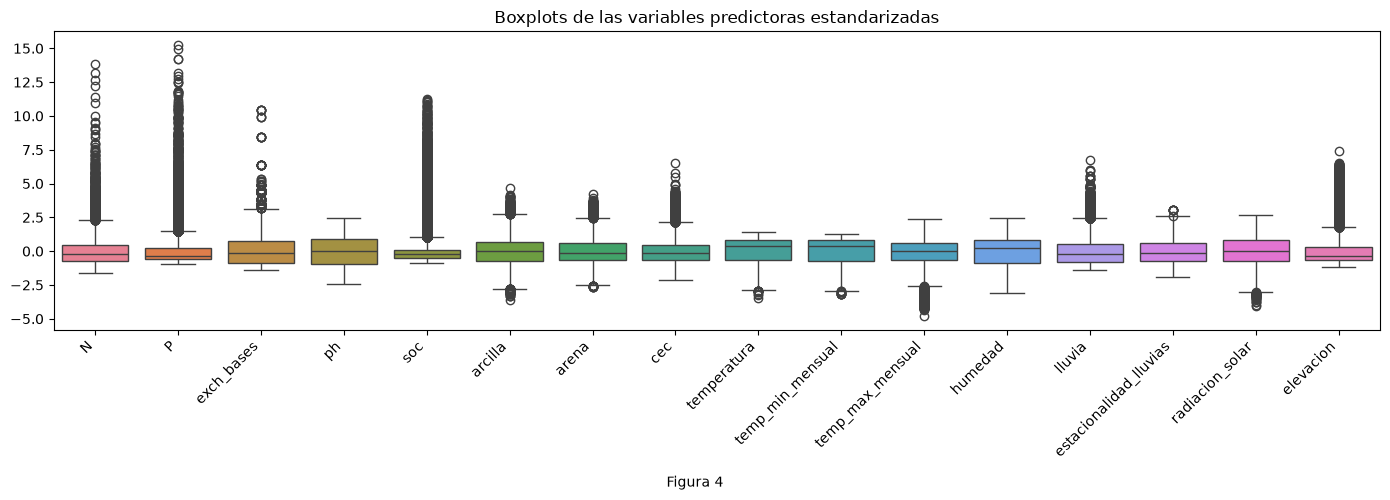

In [12]:
# Grafico los boxplots de las variables estandarizadas para ver los atípicos que conservamos
plt.figure(figsize=(14, 5))
sns.boxplot(data=X_std)
plt.xticks(rotation=45, ha="right")
plt.title("Boxplots de las variables predictoras estandarizadas")
numerar(4)
plt.show()


Figura 4. Los atípicos que conservamos se ven en la escala estandarizada: P llega a 15.3 desvíos, N a 13.8, soc a 11.3, exch_bases a 10.4, elevacion a 7.4 y lluvia a 6.7. ph y humedad no tienen puntos fuera de las barras, ya sin las dos filas imposibles. temperatura, temp_min_mensual, temp_max_mensual y radiacion_solar solo tienen atípicos por debajo. Estas colas entran tal cual en los modelos.

## 2. SVM con kernel lineal

Exploramos C en 0.01, 0.1, 1, 10 y 100 con SVC(kernel="linear"). Cada valor se evalúa con validación cruzada estratificada de 5 folds sobre las 49803 filas limpias, con el StandardScaler dentro del pipeline. Reportamos media y desvío de Precision weighted, Recall weighted y Accuracy, y elegimos por Accuracy media.

Hipótesis: los picos múltiples de la Figura 1 indican que los cultivos se solapan en las variables, así que un hiperplano no los separa bien. Esperamos una Accuracy moderada y poca sensibilidad a C, porque la limitación está en el kernel y no en la regularización.

In [13]:
# REVISAR: no está en los apuntes. StratifiedKFold se importa en U6_Ensambles pero no se usa (mantiene la proporción de clases en cada fold); scoring como diccionario con refit calcula las tres métricas por fold y elige el modelo por Accuracy; mean_fit_time es el tiempo medio de entrenamiento por fold de cv_results_
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"precision": "precision_weighted", "recall": "recall_weighted", "accuracy": "accuracy"}


# Defino una función que arma la tabla de resultados de un GridSearchCV (media y desvío de los 5 folds)
def resumen(grid):
    res = pd.DataFrame(grid.cv_results_)
    params = [c for c in res.columns if c.startswith("param_")]
    out = res[params].rename(columns=lambda c: c.replace("param_svc__", "").replace("param_", ""))
    for m in scoring:
        out[f"{m} media"] = res[f"mean_test_{m}"]
        out[f"{m} std"] = res[f"std_test_{m}"]
    out["tiempo de fit (s)"] = res["mean_fit_time"]
    return out


Definimos una sola validación cruzada y la reutilizamos en las Actividades 2, 3 y 4, así las tres comparaciones usan los mismos folds. Tres elementos no figuran en los apuntes:

- StratifiedKFold: U6_Ensambles lo importa y no lo usa. Con shuffle=True mezcla las filas antes de armar los folds, necesario porque el CSV está ordenado por clase (10 bloques seguidos, uno por clase).
- scoring como diccionario: calcula Precision weighted, Recall weighted y Accuracy en cada fold. refit="accuracy" indica con qué métrica GridSearchCV elige la configuración y reentrena el mejor modelo con todos los datos.
- mean_fit_time: columna de cv_results_ con el tiempo medio de entrenamiento por fold. La usamos para comparar tiempos en la Actividad 5. Los 5 folds corren en paralelo (n_jobs=-1), así que los tiempos sirven para comparar entre configuraciones y modelos, y no como medida aislada.

In [14]:
# Busco C con GridSearchCV sobre todo el conjunto limpio; el StandardScaler va dentro del pipeline
grid_lineal = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear", random_state=SEED)),
                           {"svc__C": [0.01, 0.1, 1, 10, 100]},
                           cv=skf, scoring=scoring, refit="accuracy", n_jobs=-1)
grid_lineal.fit(X, y)
res_lineal = resumen(grid_lineal)
display(res_lineal.round(4))
print("Mejor configuración:", grid_lineal.best_params_)


,C,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
0,0.01,0.6048,0.0044,0.6048,0.0036,0.6048,0.0036,44.4812
1,0.10,0.6172,0.0056,0.6179,0.0050,0.6179,0.0050,51.1027
2,1.00,0.6219,0.0052,0.6219,0.0049,0.6219,0.0049,97.8231
3,10.00,0.6230,0.0049,0.6230,0.0047,0.6230,0.0047,165.5184
4,100.00,0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,637.4545


Mejor configuración: {'svc__C': 100}


Resultados: la Accuracy media es 0.6048 con C=0.01, 0.6179 con C=0.1, 0.6219 con C=1, 0.6230 con C=10 y 0.6232 con C=100. Precision y Recall weighted quedan prácticamente iguales a la Accuracy (0.6232 y 0.6232 con C=100), con desvíos entre 0.0036 y 0.0056.

Seleccionamos C=100 por tener la Accuracy media más alta. De C=1 en adelante las diferencias son de 0.0013 o menos, menores que el desvío (0.0047 a 0.0049), así que esas tres configuraciones rinden igual. Lo que cambia es el tiempo medio de entrenamiento por fold: 98 s con C=1 y 637 s con C=100.

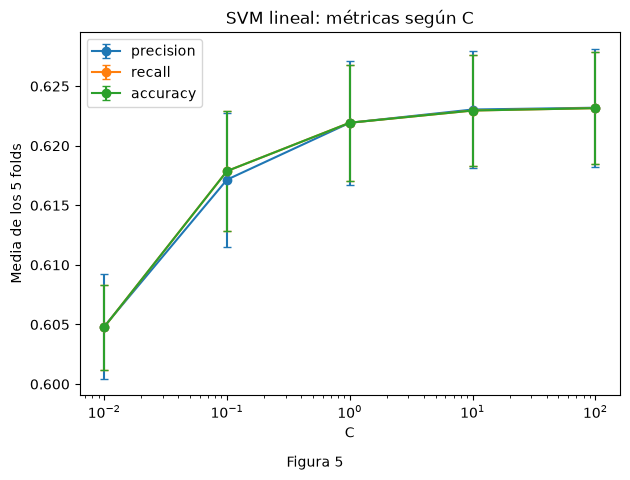

In [15]:
# Grafico las tres métricas medias con su desvío en función de C
for m in scoring:
    plt.errorbar(res_lineal["C"], res_lineal[f"{m} media"], yerr=res_lineal[f"{m} std"],
                 marker="o", capsize=3, label=m)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Media de los 5 folds")
plt.title("SVM lineal: métricas según C")
plt.legend()
numerar(5)
plt.show()


Figura 5. La Accuracy sube de 0.6048 (C=0.01) a 0.6219 (C=1) y se aplana: de 1 a 100 gana solo 0.0013. Las tres métricas se superponen y las barras de error cubren las diferencias entre C=1, 10 y 100. Toda la curva se mueve en un rango de 0.0184 (de 0.6048 a 0.6232). Coincide con la hipótesis: la Accuracy ronda 0.62 y C cambia poco el resultado, así que el límite lo pone la frontera lineal.

## 3. SVM con kernel gaussiano (RBF)

Probamos C en 0.1, 1, 10 y 100, y gamma en 0.001, 0.01, 0.1 y 1 (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold y el mismo pipeline.

Hipótesis: el RBF mejora mucho al lineal, porque el solapamiento entre cultivos no es lineal. Con gamma chico esperamos subajuste, y la mejor zona con C y gamma medios o altos.

In [16]:
# Busco C y gamma con GridSearchCV (16 combinaciones) sobre todo el conjunto limpio
param_rbf = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
grid_rbf = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)),
                        param_rbf, cv=skf, scoring=scoring, refit="accuracy", n_jobs=-1)
grid_rbf.fit(X, y)
res_rbf = resumen(grid_rbf)
display(res_rbf.sort_values("accuracy media", ascending=False).round(4))
print("Mejor configuración:", grid_rbf.best_params_)


,C,gamma,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
11,10.0,1.000,0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,90.3932
14,100.0,0.100,0.8841,0.0018,0.8850,0.0018,0.8850,0.0018,32.3948
7,1.0,1.000,0.8834,0.0029,0.8812,0.0029,0.8812,0.0029,80.7741
15,100.0,1.000,0.8826,0.0023,0.8805,0.0027,0.8805,0.0027,59.6744
10,10.0,0.100,0.8678,0.0038,0.8688,0.0038,0.8688,0.0038,23.2494
6,1.0,0.100,0.8239,0.0032,0.8244,0.0034,0.8244,0.0034,25.1999
13,100.0,0.010,0.8054,0.0039,0.8061,0.0039,0.8061,0.0039,40.4571
3,0.1,1.000,0.8271,0.0055,0.7611,0.0063,0.7611,0.0063,95.1685
9,10.0,0.010,0.7516,0.0062,0.7510,0.0059,0.7510,0.0059,34.0238
2,0.1,0.100,0.7421,0.0043,0.7413,0.0046,0.7413,0.0046,41.0439


Mejor configuración: {'svc__C': 10, 'svc__gamma': 1}


Mejor configuración: C=10 y gamma=1, con Accuracy 0.8864 ± 0.0035, Precision 0.8881 ± 0.0033 y Recall 0.8864 ± 0.0035. Le siguen C=100 con gamma=0.1 (0.8850 ± 0.0018) y C=1 con gamma=1 (0.8812 ± 0.0029), las tres dentro de un desvío.

Elegimos C=10 y gamma=1 por la Accuracy media más alta. C=100 con gamma=0.1 tiene el menor desvío de la tabla (0.0018) y entrena más rápido (32 s por fold contra 90 s), así que es una alternativa razonable. El mejor gamma está en el borde de la grilla (1), y un valor mayor podría rendir algo más. No lo probamos porque la grilla pedida llega hasta 1.

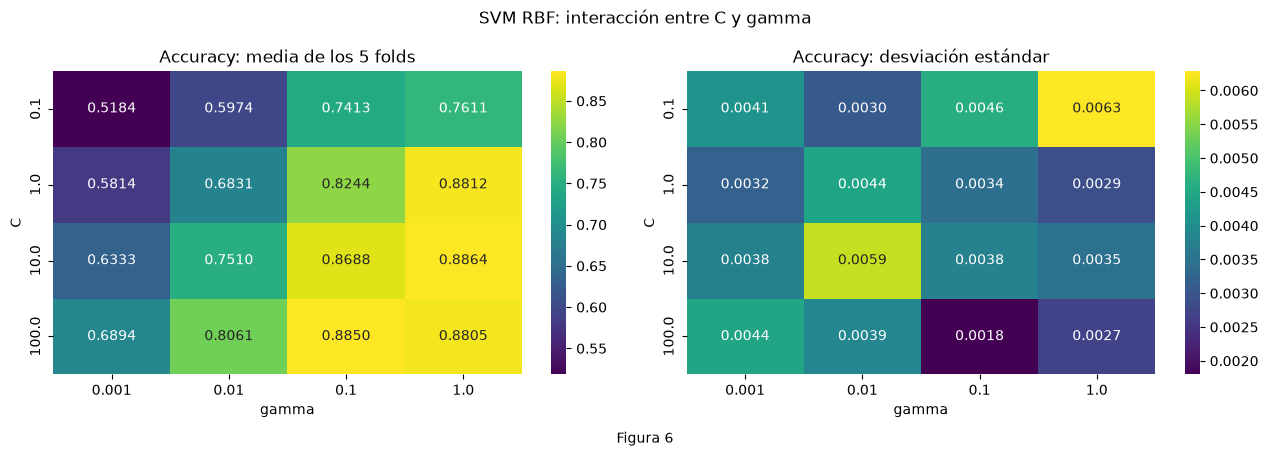

In [17]:
# REVISAR: no está en los apuntes. pivot reordena la tabla con C en las filas y gamma en las columnas para dibujar el mapa de calor
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rbf.pivot(index="C", columns="gamma", values=col), annot=True, fmt=".4f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("SVM RBF: interacción entre C y gamma")
numerar(6)
plt.show()


El mapa de calor usa pivot de pandas, que no figura en los apuntes: reordena la tabla de resultados con C en las filas y gamma en las columnas.

Figura 6. Con C=0.1 la Accuracy va de 0.5184 (gamma=0.001) a 0.7611 (gamma=1). Con gamma=0.001 no pasa de 0.6894 aunque C llegue a 100, y esa columna subajusta, como esperábamos. La zona con C de 1 en adelante y gamma de 0.1 en adelante concentra los valores altos, entre 0.8244 y 0.8864. Con gamma=1 el aumento de C se frena: de C=10 a C=100 la Accuracy baja de 0.8864 a 0.8805. El mapa del desvío va de 0.0018 (C=100, gamma=0.1) a 0.0063 (C=0.1, gamma=1).

El RBF (0.8864) supera al lineal (0.6232) por 0.2632, y la hipótesis se cumple.

## 4. Random Forest

Probamos n_estimators en 50, 100, 200 y 500, y max_depth en 5, 10, 20 y None (16 combinaciones y 80 entrenamientos), con el mismo StratifiedKFold. El Random Forest se entrena con X sin estandarizar.

Hipótesis: el Random Forest supera al RBF, porque cortes por umbral sobre las variables climáticas separan bien los cultivos. max_depth pesa más que n_estimators. Las variables de clima y ubicación (temperaturas, lluvia, humedad, radiación, elevación) lideran la importancia, por encima de las de suelo.

In [18]:
# Busco n_estimators y max_depth con GridSearchCV (16 combinaciones); Random Forest se entrena sin estandarizar
param_rf = {"n_estimators": [50, 100, 200, 500], "max_depth": [5, 10, 20, None]}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=SEED), param_rf,
                       cv=skf, scoring=scoring, refit="accuracy", n_jobs=-1)
grid_rf.fit(X, y)
res_rf = resumen(grid_rf)
display(res_rf.sort_values("accuracy media", ascending=False).round(4))
print("Mejor configuración:", grid_rf.best_params_)


,max_depth,n_estimators,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
15,None,500,0.9162,0.0035,0.9167,0.0035,0.9167,0.0035,73.5903
14,None,200,0.9149,0.0037,0.9154,0.0037,0.9154,0.0037,33.4676
13,None,100,0.9144,0.0031,0.9149,0.0031,0.9149,0.0031,16.5679
11,20,500,0.9138,0.0038,0.9141,0.0038,0.9141,0.0038,79.2986
10,20,200,0.9133,0.0035,0.9137,0.0035,0.9137,0.0035,31.4394
12,None,50,0.9131,0.0036,0.9137,0.0036,0.9137,0.0036,8.1356
9,20,100,0.9119,0.0028,0.9124,0.0029,0.9124,0.0029,15.7582
8,20,50,0.9101,0.0033,0.9105,0.0033,0.9105,0.0033,7.8802
7,10,500,0.8458,0.0045,0.8430,0.0047,0.8430,0.0047,55.2162
6,10,200,0.8448,0.0046,0.8422,0.0048,0.8422,0.0048,22.2072


Mejor configuración: {'max_depth': None, 'n_estimators': 500}


Mejor configuración: max_depth=None y n_estimators=500, con Accuracy 0.9167 ± 0.0035, Precision 0.9162 ± 0.0035 y Recall 0.9167 ± 0.0035.

max_depth pesa mucho: con 5 la Accuracy está entre 0.6385 y 0.6456, con 10 entre 0.8394 y 0.8430, y con 20 o None entre 0.9105 y 0.9167. n_estimators pesa poco: con max_depth=None, pasar de 50 a 500 árboles sube la Accuracy de 0.9137 a 0.9167, una diferencia de 0.0030 menor que el desvío (0.0035).

Elegimos max_depth=None y n_estimators=500 por la Accuracy media más alta. Con 50 árboles y max_depth=None la Accuracy es 0.9137 y el entrenamiento tarda 8 s por fold, contra 74 s de la elegida. Esa configuración sería la opción si el tiempo importara más.

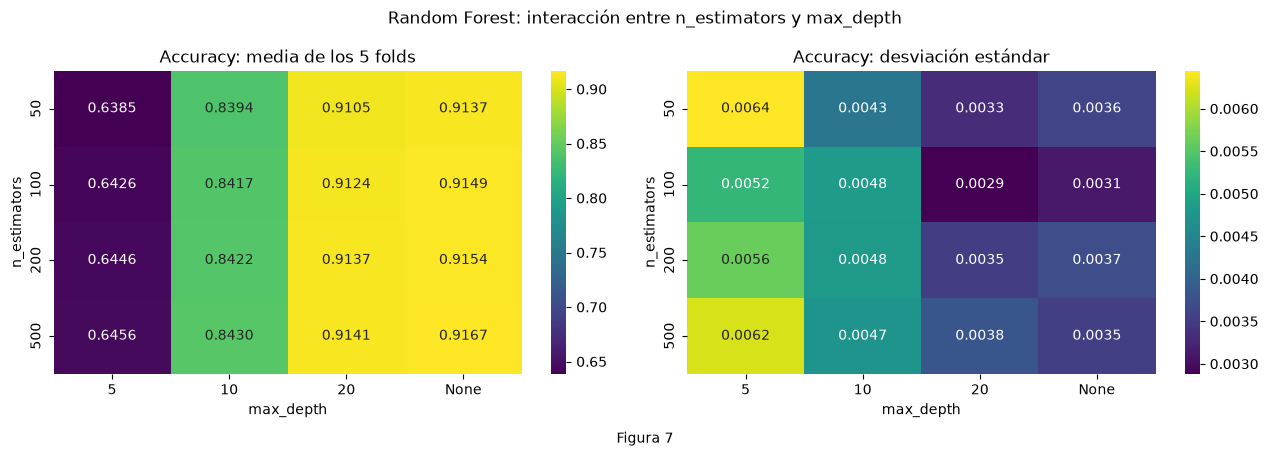

In [19]:
# REVISAR: no está en los apuntes. pivot reordena la tabla con n_estimators en las filas y max_depth en las columnas para dibujar el mapa de calor
res_rf["max_depth"] = res_rf["max_depth"].map(str)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, titulo) in zip(axes, [("accuracy media", "Accuracy: media de los 5 folds"),
                                    ("accuracy std", "Accuracy: desviación estándar")]):
    sns.heatmap(res_rf.pivot(index="n_estimators", columns="max_depth", values=col)[["5", "10", "20", "None"]],
                annot=True, fmt=".4f", cmap="viridis", ax=ax)
    ax.set_title(titulo)
plt.suptitle("Random Forest: interacción entre n_estimators y max_depth")
numerar(7)
plt.show()


Este mapa también usa pivot. max_depth se pasa a texto con map(str) para que None quede como columna del mapa, y tampoco está en los apuntes.

Figura 7. La Accuracy cambia sobre todo por filas de max_depth: de 5 a 10 sube cerca de 0.20 (0.6456 a 0.8430 con 500 árboles) y de 10 a 20 cerca de 0.07 (0.8430 a 0.9141). Entre 20 y None casi no hay cambio. Dentro de cada columna con max_depth de 10 en adelante, n_estimators mueve la Accuracy 0.0036 o menos. El mapa del desvío va de 0.0029 a 0.0064, con los valores más altos en max_depth=5. La hipótesis sobre max_depth y n_estimators se cumple.

,features,importances
9,temp_min_mensual,0.1172
10,temp_max_mensual,0.0922
14,radiacion_solar,0.0894
12,lluvia,0.0886
11,humedad,0.0851
8,temperatura,0.0827
13,estacionalidad_lluvias,0.0761
15,elevacion,0.0715
3,ph,0.0439
2,exch_bases,0.0405


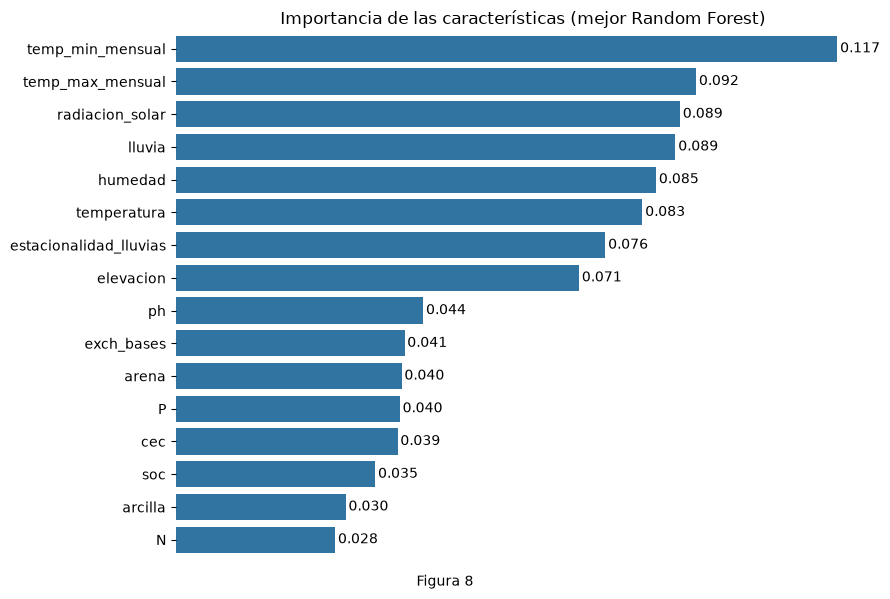

In [20]:
# Armo una tabla con la importancia de cada variable en el mejor Random Forest y la grafico
importancias = pd.DataFrame({"features": X.columns, "importances": grid_rf.best_estimator_.feature_importances_})
importancias = importancias.sort_values(by="importances", ascending=False)
display(importancias.round(4))

plt.figure(figsize=(9, 6))
g = sns.barplot(data=importancias, x="importances", y="features")
sns.despine(bottom=True, left=True)
g.set_title("Importancia de las características (mejor Random Forest)")
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2, fmt="%.3f")
numerar(8)
plt.show()


Importancias del mejor Random Forest (max_depth=None y 500 árboles, reentrenado con todos los datos): temp_min_mensual 0.1172, temp_max_mensual 0.0922, radiacion_solar 0.0894, lluvia 0.0886, humedad 0.0851, temperatura 0.0827, estacionalidad_lluvias 0.0761 y elevacion 0.0715. Las 8 variables de clima y ubicación suman 0.7028 y las 8 de suelo 0.2972. En suelo, la mayor es ph (0.0439) y la menor N (0.0283). La hipótesis se cumple.

Figura 8. Las barras repiten la tabla: las ocho primeras son de clima o ubicación y ninguna de suelo supera 0.0439. Todas las variables aportan al menos 0.0283. temperatura y temp_min_mensual tienen correlación de 0.95 (Figura 3), así que la importancia se reparte entre ellas y el orden entre ambas es poco confiable.

## 5. Comparación de modelos

La tabla reúne la mejor configuración de cada algoritmo según la validación cruzada de las Actividades 2 a 4, con media y desvío de los 5 folds y el tiempo medio de entrenamiento por fold. Para las matrices de confusión separamos un 20 % de test estratificado con random_state=13 (9961 filas), entrenamos cada mejor modelo con el 80 % restante y predecimos el test.

In [21]:
# Armo la tabla comparativa con la mejor configuración de cada algoritmo
grids = {"SVM lineal": grid_lineal, "SVM RBF": grid_rbf, "Random Forest": grid_rf}
columnas = ["precision media", "precision std", "recall media", "recall std",
            "accuracy media", "accuracy std", "tiempo de fit (s)"]
comparacion = pd.DataFrame({nombre: resumen(g).loc[g.best_index_, columnas] for nombre, g in grids.items()}).T
comparacion.insert(0, "configuración", [g.best_params_ for g in grids.values()])
display(comparacion.round(4))


,configuración,precision media,precision std,recall media,recall std,accuracy media,accuracy std,tiempo de fit (s)
SVM lineal,{'svc__C': 100},0.6232,0.0050,0.6232,0.0047,0.6232,0.0047,637.4545
SVM RBF,"{'svc__C': 10, 'svc__gamma': 1}",0.8881,0.0033,0.8864,0.0035,0.8864,0.0035,90.3932
Random Forest,"{'max_depth': None, 'n_estimators': 500}",0.9162,0.0035,0.9167,0.0035,0.9167,0.0035,73.5903


Resultados de la validación cruzada (Precision weighted, Recall weighted y Accuracy, media ± desvío):

- SVM lineal (C=100): 0.6232 ± 0.0050, 0.6232 ± 0.0047 y 0.6232 ± 0.0047, con 637 s de entrenamiento por fold.
- SVM RBF (C=10, gamma=1): 0.8881 ± 0.0033, 0.8864 ± 0.0035 y 0.8864 ± 0.0035, con 90 s.
- Random Forest (max_depth=None, 500 árboles): 0.9162 ± 0.0035, 0.9167 ± 0.0035 y 0.9167 ± 0.0035, con 74 s.

El Random Forest supera al RBF por 0.0303 de Accuracy, casi nueve veces el desvío (0.0035), y el RBF supera al lineal por 0.2632. Los desvíos del RBF y del Random Forest son iguales (0.0035) y el del lineal es mayor (0.0047), así que los dos primeros son igual de estables entre folds.

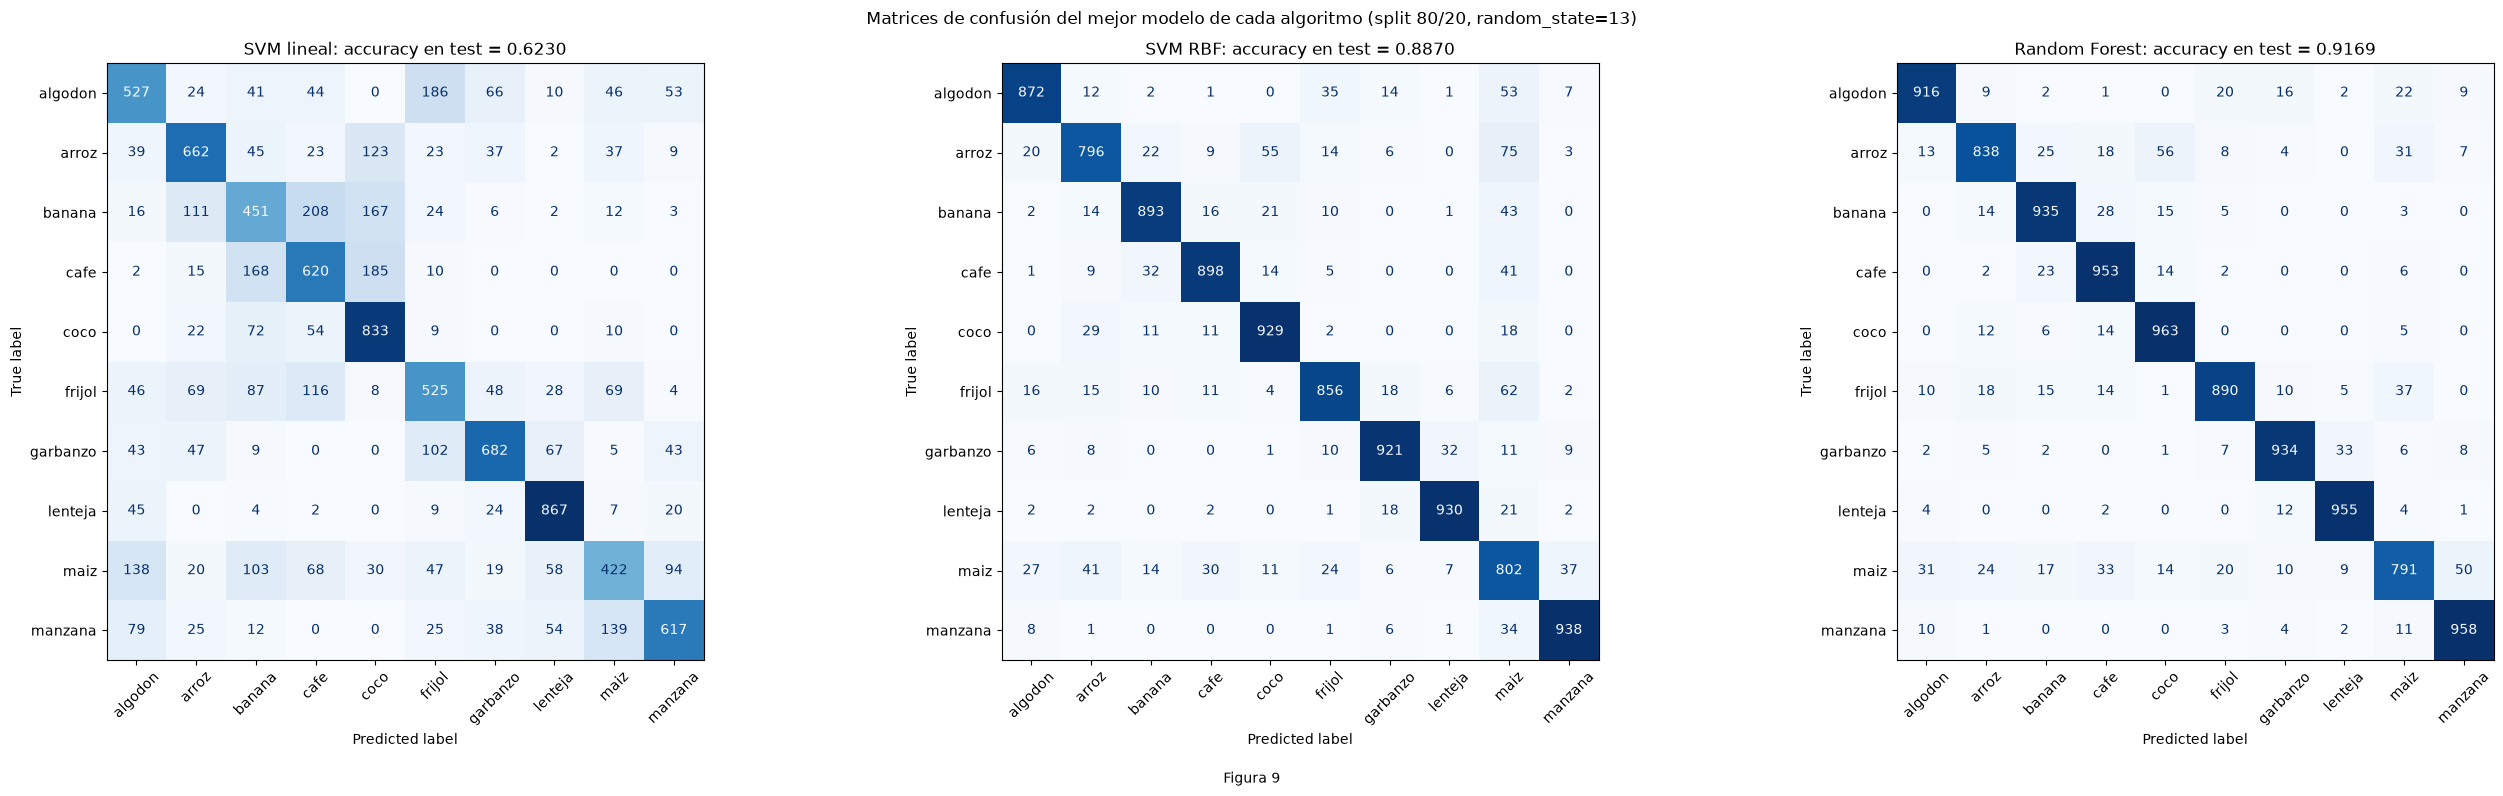

In [22]:
# Separo un 20 % de test (random_state=13), entreno el mejor modelo de cada algoritmo y grafico sus matrices de confusión
Xtrn, Xtst, ytrn, ytst = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
fig, axes = plt.subplots(1, 3, figsize=(27, 8))
for ax, (nombre, g) in zip(axes, grids.items()):
    pred = g.best_estimator_.fit(Xtrn, ytrn).predict(Xtst)
    ConfusionMatrixDisplay.from_predictions(ytst, pred, display_labels=le.classes_, ax=ax,
                                            cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{nombre}: accuracy en test = {accuracy_score(ytst, pred):.4f}")
plt.suptitle("Matrices de confusión del mejor modelo de cada algoritmo (split 80/20, random_state=13)")
numerar(9)
plt.show()


Figura 9. En el test de 9961 filas la Accuracy es 0.6230 (lineal), 0.8870 (RBF) y 0.9169 (Random Forest), casi iguales a las de validación cruzada. Cada clase tiene cerca de 1000 casos.

El lineal confunde sobre todo banana, cafe y coco entre sí: banana se predice como cafe 208 veces y como coco 167, y cafe como coco 185 y como banana 168. Su Recall por clase va de 0.422 (maiz) a 0.887 (lenteja). El RBF y el Random Forest tienen la diagonal mucho más marcada. El RBF tiende a predecir maiz de más: arroz (75), frijol (62), algodon (53), banana (43) y cafe (41) caen en esa columna. En el Random Forest los errores se reparten más, con arroz como coco (56), maiz como manzana (50) y frijol como maiz (37). maiz tiene el Recall más bajo en el Random Forest (0.792) y arroz en el RBF (0.796). Garbanzo se predice como lenteja 32 veces en el RBF y 33 en el Random Forest.

Elegimos el Random Forest:

- Tiene las mejores métricas: Accuracy de 0.9167 en validación cruzada y de 0.9169 en test, contra 0.8864 y 0.8870 del RBF.
- Es tan estable como el RBF (desvío de 0.0035) y más estable que el lineal (0.0047).
- Entrena en 74 s por fold, contra 90 s del RBF y 637 s del lineal.
- Entrega la importancia de las variables (Figura 8) y muestra qué variables mueven la recomendación. El RBF no da esa lectura.
- Con 50 árboles baja a 8 s por fold y pierde 0.0030 de Accuracy, si hiciera falta un modelo más rápido.

El lineal queda descartado por su Accuracy de 0.6232. El RBF es la segunda opción, con el mismo desvío que el Random Forest.

# Conclusiones

Preparación de datos:

- Eliminamos 201 de 50004 filas: 198 duplicadas (109 de lenteja y 55 de manzana entre ellas), 1 con tres nulos (ph, cec y humedad) y 2 con valores imposibles (ph de 25.317 y 18.017, humedad de 148.141 y arcilla de 142.383).
- Conservamos los atípicos por IQR de soc (7.3%), P (6.9%) y elevacion (5.6%), que son colas largas posibles. El conjunto limpio tiene 49803 filas y una razón entre clases de 1.022.
- Estandarizamos dentro de un pipeline en cada fold, para que el fold de test no influya en la media ni en el desvío.

Modelos (validación cruzada estratificada de 5 folds, Accuracy media ± desvío):

- SVM lineal: 0.6232 ± 0.0047 con C=100. De C=1 en adelante las diferencias son de 0.0013 o menos, así que C casi no importa.
- SVM RBF: 0.8864 ± 0.0035 con C=10 y gamma=1. Mejora al lineal en 0.2632. El mejor gamma está en el borde de la grilla.
- Random Forest: 0.9167 ± 0.0035 con max_depth=None y 500 árboles. max_depth pesa más que n_estimators.
- Importancias: las 8 variables de clima y ubicación suman 0.7028 y las 8 de suelo 0.2972. La mayor es temp_min_mensual (0.1172).
- Elegimos el Random Forest por sus métricas, su estabilidad, su tiempo de entrenamiento y la lectura de importancias. En test llega a 0.9169, contra 0.8870 del RBF y 0.6230 del lineal.

Balance de hipótesis:

- Se cumplieron: P, soc, lluvia y elevacion tienen cola derecha; el SVM lineal rinde poco y casi no depende de C; el RBF supera al lineal y subajusta con gamma chico; el Random Forest supera al RBF; max_depth pesa más que n_estimators; las variables de clima y ubicación lideran la importancia.
- Se cumplieron en parte: las temperaturas están correlacionadas, pero temp_min_mensual y temp_max_mensual solo llegan a 0.52 entre sí.
- Distinto de lo esperado: el enunciado menciona un leve desbalance y el archivo original tenía 5000 filas por clase. El desbalance (razón de 1.022) aparece al eliminar duplicados. maiz resultó la clase más difícil: Recall de 0.422 con el lineal y de 0.792 con el Random Forest.

Limitaciones: las grillas son las que pide el enunciado y el RBF queda en su borde. Las filas del test de la Figura 9 también participaron en la selección de hiperparámetros por validación cruzada, así que la comparación principal es la de validación cruzada. Los tiempos se midieron con los folds en paralelo. Usamos una sola semilla (13).